# Figure S2d
Standard deviation $\sigma_H$ of $H$ divided by $\sqrt{N}$ against the population size. Markers are exact, solid curves are the variance of the theorem without the exponentially small term, and dashed lines are the leading order $\sqrt{r(r+1)/(r-1)^3}$.

In [1]:
import json

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

from fixloc import style as S

d = json.load(open('data.json'))

In [2]:
CM_R = LinearSegmentedColormap.from_list('r', [S.LBLUE, S.BLUE, (0.03, 0.15, 0.35)])
RCOL = {r: CM_R(x) for r, x in zip(d['rs'], (0.2, 0.47, 0.74, 1.0))}
DASH = (0, (3, 2))

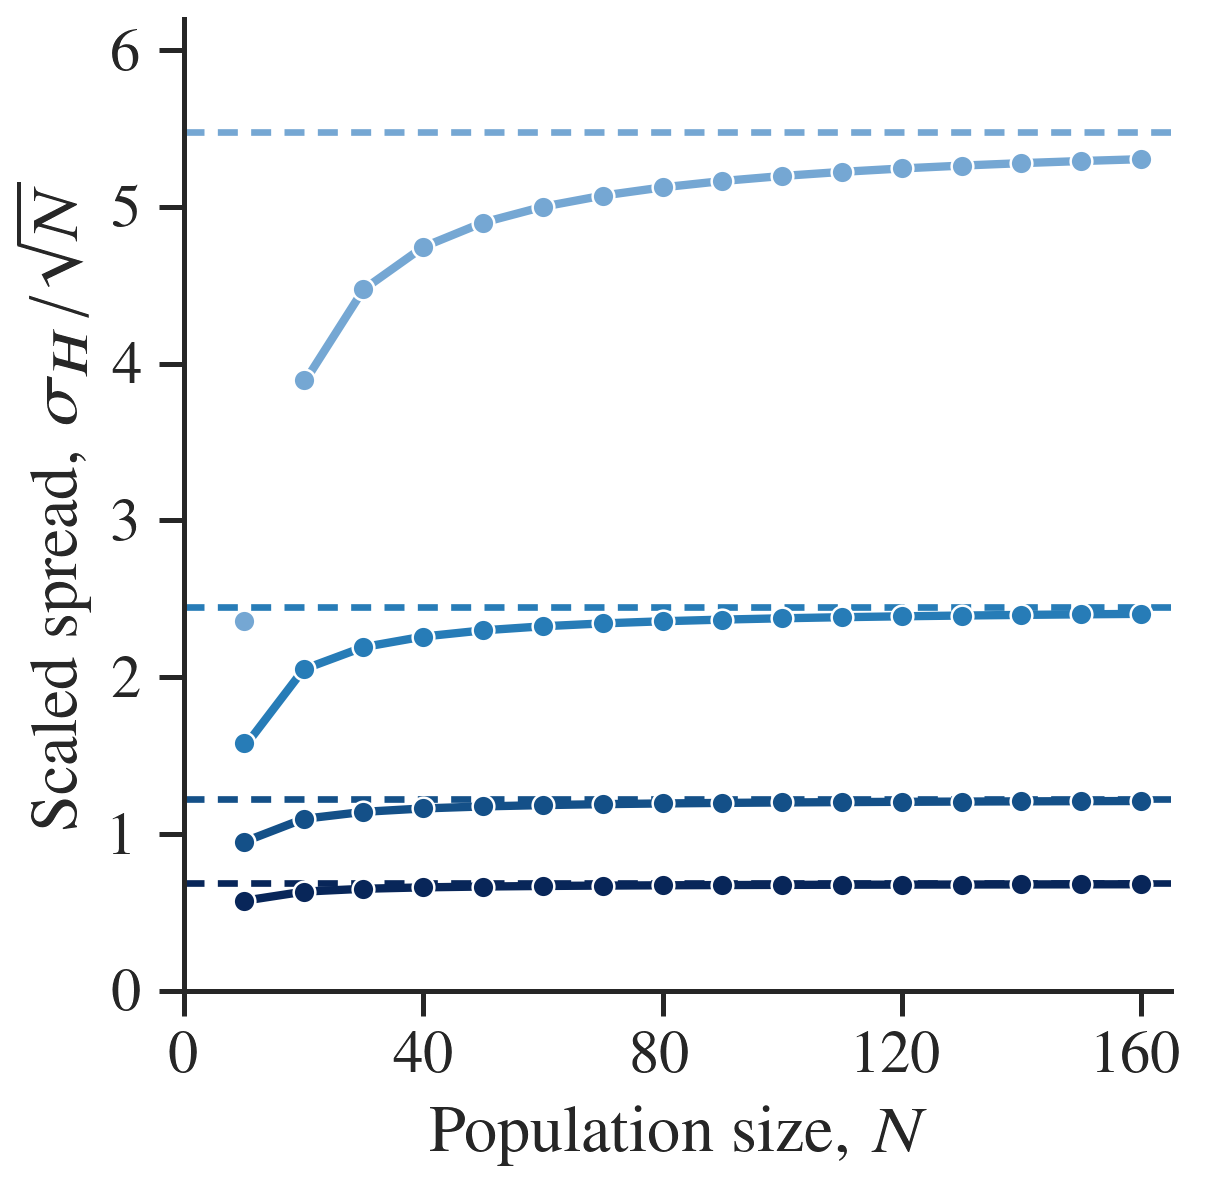

In [3]:
Nd = np.array(d['N'])
fig = plt.figure(figsize=(7.0, 5.4))
ax = fig.add_axes([0.735, 0.085, 0.235, 0.3])
for r in d['rs']:
  s = d['spread'][str(r)]
  cor = np.array(s['corrected'])
  ok = cor > 0
  ax.plot(Nd, s['sd_over_sqrtN'], ls='', marker='o', ms=2.6, mfc=RCOL[r], mec='white', mew=0.3, zorder=3)
  ax.plot(Nd[ok], cor[ok], color=RCOL[r], lw=1.0, zorder=2)
  ax.axhline(s['drift_level'], color=RCOL[r], lw=0.8, ls=DASH, zorder=1)
ax.set_xlim(0, 165)
ax.set_ylim(0, 6.2)
ax.set_xticks([0, 40, 80, 120, 160])
ax.set_xlabel(r'Population size, $N$')
ax.set_ylabel(r'Scaled spread, $\sigma_H/\sqrt{N}$')
S.save_panel(fig, 'd')